In [2]:
import requests
import pandas as pd
from datetime import datetime

# Fetch top 10 crypto prices from CoinGecko (free, no API key needed)
url = "https://api.coingecko.com/api/v3/coins/markets"
params = {
    'vs_currency': 'usd',
    'order': 'market_cap_desc',
    'per_page': 10,
    'page': 1
}

response = requests.get(url, params=params)
data = response.json()

print("Status code:", response.status_code)
print("Number of coins fetched:", len(data))
print("First coin:", data[0]['name'], "-", data[0]['current_price'], "USD")

Status code: 200
Number of coins fetched: 10
First coin: Bitcoin - 80609 USD


In [3]:
# Extract only the fields we need
df_crypto = pd.DataFrame([{
    'name': coin['name'],
    'symbol': coin['symbol'].upper(),
    'current_price_usd': coin['current_price'],
    'market_cap': coin['market_cap'],
    'price_change_24h_pct': coin['price_change_percentage_24h'],
    'high_24h': coin['high_24h'],
    'low_24h': coin['low_24h'],
    'last_updated': coin['last_updated']
} for coin in data])

# Add timestamp of when we fetched this data
df_crypto['fetched_at'] = datetime.now().strftime('%Y-%m-%d %H:%M:%S')

print("Shape:", df_crypto.shape)
print("\nTop 10 Cryptocurrencies:")
print(df_crypto[['name', 'symbol', 'current_price_usd', 'price_change_24h_pct']])

Shape: (10, 9)

Top 10 Cryptocurrencies:
           name      symbol  current_price_usd  price_change_24h_pct
0       Bitcoin         BTC       80609.000000               1.05558
1      Ethereum         ETH        2341.550000               1.06124
2        Tether        USDT           0.999028              -0.00517
3           BNB         BNB         740.950000               2.59830
4           XRP         XRP           1.300000               2.64059
5          USDC        USDC           0.999568              -0.01004
6        Solana         SOL         101.540000               1.83565
7          TRON         TRX           0.328758              -0.04200
8  Figure Heloc  FIGR_HELOC           1.056000               3.36982
9         Zcash         ZEC        1213.320000               6.87254


In [4]:
# Analysis
print("=" * 50)
print("CRYPTO MARKET SUMMARY")
print("=" * 50)
print(f"Most expensive coin:  {df_crypto.loc[df_crypto['current_price_usd'].idxmax(), 'name']} (${df_crypto['current_price_usd'].max():,.2f})")
print(f"Biggest gainer (24h): {df_crypto.loc[df_crypto['price_change_24h_pct'].idxmax(), 'name']} (+{df_crypto['price_change_24h_pct'].max():.2f}%)")
print(f"Biggest loser (24h):  {df_crypto.loc[df_crypto['price_change_24h_pct'].idxmin(), 'name']} ({df_crypto['price_change_24h_pct'].min():.2f}%)")
print(f"Data fetched at:      {df_crypto['fetched_at'][0]}")
print("=" * 50)

# Save to CSV
df_crypto.to_csv(r"C:\Users\PAVITHRA S\Downloads\crypto_prices.csv", index=False)
print("\nData saved to crypto_prices.csv!")

CRYPTO MARKET SUMMARY
Most expensive coin:  Bitcoin ($80,609.00)
Biggest gainer (24h): Zcash (+6.87%)
Biggest loser (24h):  TRON (-0.04%)
Data fetched at:      2026-10-25 20:44:09

Data saved to crypto_prices.csv!


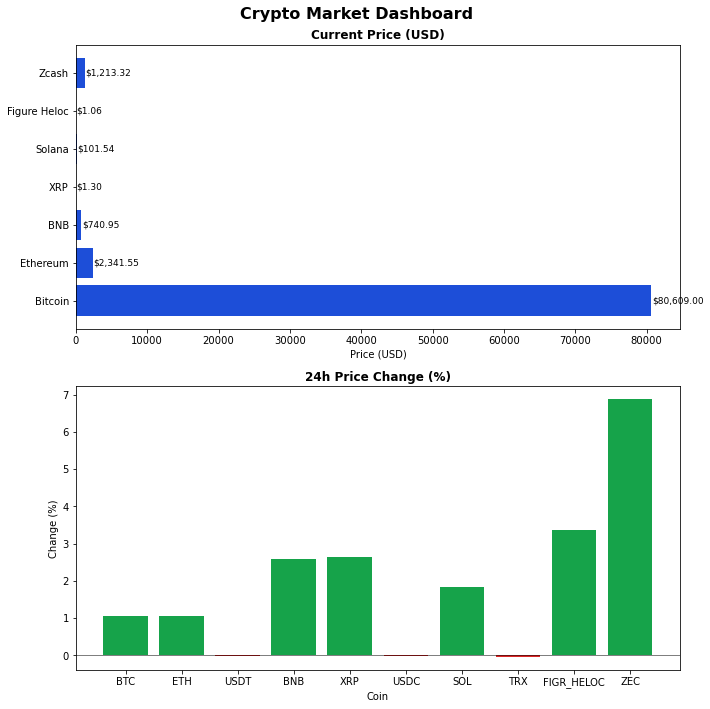

Chart saved!


In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(10, 10))
fig.suptitle("Crypto Market Dashboard", fontsize=16, fontweight="bold")

# Chart 1 — Current prices (excluding stablecoins)
df_volatile = df_crypto[df_crypto['current_price_usd'] > 1].copy()
axes[0].barh(df_volatile['name'], df_volatile['current_price_usd'], color='#1D4ED8')
axes[0].set_title("Current Price (USD)", fontweight="bold")
axes[0].set_xlabel("Price (USD)")
for i, v in enumerate(df_volatile['current_price_usd']):
    axes[0].text(v + 100, i, f"${v:,.2f}", va='center', fontsize=9)

# Chart 2 — 24h price change
colors = ['#16A34A' if x > 0 else '#DC2626' 
          for x in df_crypto['price_change_24h_pct']]
axes[1].bar(df_crypto['symbol'], df_crypto['price_change_24h_pct'], color=colors)
axes[1].set_title("24h Price Change (%)", fontweight="bold")
axes[1].set_xlabel("Coin")
axes[1].set_ylabel("Change (%)")
axes[1].axhline(y=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.savefig(r"C:\Users\PAVITHRA S\Downloads\crypto_dashboard.png", 
            dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved!")